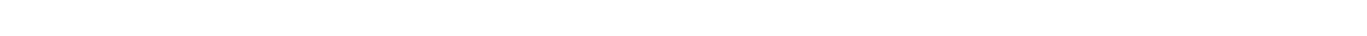

In [ ]:
import marimo as mo

# NB 1.01: Fine-tune Llama-3.2-1B-Instruct (LoRA) on dataset v2, one question per request

| | |
|---|---|
| **Experiment(s)** | `f1`: first fine-tune of the student model (RESEARCH_LOG decisions 2026-11-11), compared with baseline b2 (NB 2.02/2.02b) |
| **Paper / report** | Results Summary §6.1 (f1 rows next to b2), §6.2 later (phone) |
| **Env** | Marimo machine with a GPU (RTX 6000 class); the kernel's torch + transformers (installed only if absent), `peft`, `accelerate`, `xgrammar` |
| **Inputs** | HF dataset `emmilly/vnest-exercise-llm-outputs`: `data/v2/{train,validation,test}.jsonl` + `SHA256SUMS` (checked). Base model `meta-llama/Llama-3.2-1B-Instruct` (**gated**: the HF account must have accepted Meta's Llama 3.2 licence) |
| **Outputs** | Model repo `emmilly/vnest-exercise-llm-f1-llama32-1b-instruct-lora-r16` (private while `MODEL_REPOS_PRIVATE`): merged bf16 model at the root (input for the phone conversion), `epochs/epoch-N/` (each epoch's LoRA adapter), `last-checkpoint/` (resume point, removed by nothing: small). Outputs repo: `runs/f1-…/` (config, train log, select.json, raw generations, resources, `_done/`), `preds/f1__1.01__<run>__<split>__<model>-<protocol>-<dec>.csv`, `tables/f1__1.01__{forced-summary,forced-by-part,chain-summary,per-verb}.csv`. W&B `team-me-and-me/vnest-exercise-llm`, run id = run name |
| **Training** | LoRA r 16, alpha 32, dropout 0.05 on all linear layers (q, k, v, o, gate, up, down); base frozen in bf16, adapters in fp32, bf16 mixed precision; 3 epochs, lr 2e-4 cosine, warmup 5 %, batch 16, max 384 tokens; **loss on the reply only** (the prompt is masked); seed 42; loss guard aborts on NaN / exploding loss |
| **Prompt layout** | **The phone's exact layout** (`wc.phone_prompt`: MLC's "llama-3_1" template, no "Cutting Knowledge / Today Date" lines) for training and every evaluation here. b2 (NB 2.02) used Hugging Face's template, so this notebook re-evaluates the **untuned base in the phone layout as a control** |
| **Checkpoint selection** | Each epoch's adapter on validation (forced protocol, JSON rule, greedy), strict scorer (module 1.2.0): highest % of questions accepted, ties → lower validation loss. **Never on test** |
| **Evaluation** | Same protocols as b2: forced (reference earlier answers, greedy) and chain (the app's way: own answers, ≤ 3 tries per question, temperature 0.3, seed 20261111) × decoding schema (app JSON rule) / free, validation + test. Scores automatic only |
| **Keys** | KEYS cell below (HF token of `emmilly`: WRITE access + Llama 3.2 access; W&B API key), or env vars `HF_TOKEN` / `WANDB_API_KEY`. **Put the placeholders back before exporting the notebook** |
| **How to run** | Interactive: open in Marimo (Settings → Runtime → on cell change: **lazy**), run all. Unattended: `mkdir -p ~/vnest/logs && nohup python 01_lora_llama32_1b_v2.py > ~/vnest/logs/1.01_lora.log 2>&1 &` then `tail -f ~/vnest/logs/1.01_lora.log` |
| **Memory / batch** | ≈ 10 GB GPU at batch 16 × 384 tokens; generation batch 32 halves itself on out-of-memory |
| **Resume after a crash** | train resumes from `last-checkpoint/` on HF (any machine); select / merge / eval parts are read back from HF when their marker or file exists; scoring re-runs if raw outputs changed |
| **Runtime** | ≈ 10–20 min training (3,570 examples × 3 epochs) + ≈ 5 min select + ≈ 5 min eval on an RTX 6000 |
| **Smoke test (offline)** | `VNEST_OFFLINE=1 VNEST_OFFLINE_DIR=<folder with data/v2/> VNEST_SMOKE_TRAIN=24 VNEST_LIMIT=2 python 01_….py`: tiny training, nothing uploaded, run name `…-smoke` |
| **Forked from** | none (first training notebook); generation/scoring code adapted from NB 2.02 (b2) with the phone prompt layout |

In [ ]:
# ══════════════ KEYS: paste yours between the quotes (only if not already set as environment variables) ══════════════
HF_TOKEN = "hf_YOUR_TOKEN_HERE"          # ← HF token of account emmilly, WRITE access + Llama 3.2 access (huggingface.co/settings/tokens)
WANDB_API_KEY = "wandb_YOUR_KEY_HERE"    # ← W&B API key (wandb.ai/authorize)
# ════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
# Exported .ipynb files keep whatever is pasted above: put the placeholders back before sharing a file.
if "YOUR_TOKEN" in HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")
if "YOUR_KEY" in WANDB_API_KEY:
    WANDB_API_KEY = os.environ.get("WANDB_API_KEY", "")
os.environ["HF_TOKEN"] = HF_TOKEN
if WANDB_API_KEY:
    os.environ["WANDB_API_KEY"] = WANDB_API_KEY
print(f"HF_TOKEN set: {bool(HF_TOKEN)} | WANDB_API_KEY set: {bool(WANDB_API_KEY)}")

HF_TOKEN set: True | WANDB_API_KEY set: True


In [ ]:
import gc
import hashlib
import json
import math
import os
import shutil
import sys
import time
from pathlib import Path

In [ ]:
# ───────────────────────────── config: everything tunable lives here ─────────────────────────────
NOTEBOOK = "1.01"
EXP_ID = "f1"
BASE_MODEL = "meta-llama/Llama-3.2-1B-Instruct"
MODEL_SHORT = "llama32-1b-instruct"
SMOKE_TRAIN = int(os.environ["VNEST_SMOKE_TRAIN"]) if os.environ.get("VNEST_SMOKE_TRAIN") else None  # examples (smoke test)
SMOKE = bool(SMOKE_TRAIN or os.environ.get("VNEST_LIMIT") or os.environ.get("VNEST_OFFLINE"))
VARIANT = "lora-r16-smoke" if SMOKE else "lora-r16"
RUN_NAME = f"{EXP_ID}-{MODEL_SHORT}-{VARIANT}"   # checked by wc.run_name below

LORA = {"r": 16, "lora_alpha": 32, "lora_dropout": 0.05,
        "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]}
EPOCHS = 2 if SMOKE else 3
LEARNING_RATE = 2e-4
LR_SCHEDULER = "cosine"
WARMUP_RATIO = 0.05
WEIGHT_DECAY = 0.0
TRAIN_BATCH = 1 if SMOKE else 16
GRADIENT_CHECKPOINTING = SMOKE           # only for the smoke test on a 4 GB laptop GPU; the real run doesn't need it
MAX_LEN = 384                            # prompt (≈ 120 tokens) + reply (≈ 40) fit easily; longer examples are reported
SEED = 42
LOSS_ABORT = 20.0                        # loss guard: abort if the training loss is NaN or above this after warm-up

SPLITS = ["validation", "test"]          # never select anything on test
PROTOCOLS = ["forced", "chain"]          # forced = reference earlier answers; chain = the app's way
DECODINGS = ["schema", "free"]           # schema = the app's JSON rule (xgrammar); free = none
EVAL_MODELS = ["finetuned", "base"]      # base = untuned control in the phone's prompt layout
MAX_NEW_TOKENS = 48                      # the app's limit per question (checked against wc.PART_MAX_NEW_TOKENS)
CHAIN_TEMPERATURE = 0.3                  # the app samples at 0.3; retries need sampling to differ
CHAIN_SEED = 20261111
EVAL_BATCH = 32                          # halves automatically on GPU out-of-memory
LIMIT_PER_SPLIT = int(os.environ["VNEST_LIMIT"]) if os.environ.get("VNEST_LIMIT") else None  # eval exercises per split

STAGES = {"train": True, "select": True, "merge": True, "eval": True, "score": True, "summary": True}
FORCE = set()                            # e.g. {"select"} to redo a finished stage

WORK_ROOT = Path(os.environ.get("VNEST_WORK", str(Path.home() / "vnest")))
WORK_DIR = WORK_ROOT / "runs" / RUN_NAME
WORK_DIR.mkdir(parents=True, exist_ok=True)
CFG = dict(notebook=NOTEBOOK, exp_id=EXP_ID, base_model=BASE_MODEL, variant=VARIANT, run_name=RUN_NAME, lora=LORA,
           epochs=EPOCHS, learning_rate=LEARNING_RATE, lr_scheduler=LR_SCHEDULER, warmup_ratio=WARMUP_RATIO,
           weight_decay=WEIGHT_DECAY, train_batch=TRAIN_BATCH, gradient_checkpointing=GRADIENT_CHECKPOINTING, max_len=MAX_LEN, seed=SEED, loss_on="reply only",
           prompt_layout="phone (MLC llama-3_1, wc.phone_prompt)", selection="validation forced-schema accepted % (strict)",
           splits=SPLITS, protocols=PROTOCOLS, decodings=DECODINGS, eval_models=EVAL_MODELS, max_new_tokens=MAX_NEW_TOKENS,
           chain_temperature=CHAIN_TEMPERATURE, chain_seed=CHAIN_SEED, eval_batch=EVAL_BATCH,
           limit_per_split=LIMIT_PER_SPLIT, smoke_train=SMOKE_TRAIN, smoke=SMOKE)
print(f"run {RUN_NAME} | base {BASE_MODEL} | work dir {WORK_DIR}" + (" | SMOKE TEST" if SMOKE else ""))

run f1-llama32-1b-instruct-lora-r16 | base meta-llama/Llama-3.2-1B-Instruct | work dir /home/marimo/vnest/runs/f1-llama32-1b-instruct-lora-r16


In [ ]:
# ───────────── shared module (vnest_common), embedded; regenerate with tools/make_standalone.py ─────────────
import base64 as _b64
import importlib as _il
import subprocess as _sp
_EMBED_VERSION = "1.2.0"
_EMBED_B64 = "..."  # >>> vnest_common (do not edit: tools/make_standalone.py)
for _pkg in ("huggingface_hub", "pandas", "numpy"):
    try:
        _il.import_module(_pkg)
    except ImportError:
        _sp.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=True)
_dir = Path(WORK_ROOT) / "common"
_dir.mkdir(parents=True, exist_ok=True)
(_dir / "vnest_common.py").write_bytes(_b64.b64decode(_EMBED_B64))
if str(_dir) not in sys.path:
    sys.path.insert(0, str(_dir))
import vnest_common as wc
wc = _il.reload(wc)
assert wc.VERSION == _EMBED_VERSION, (wc.VERSION, _EMBED_VERSION)
_acct = wc.whoami()
print(f"vnest_common {wc.VERSION} | HF token account: {_acct}" + (" | OFFLINE (no uploads)" if wc.offline() else ""))
if _acct != wc.HF_USER:
    print(f"WARNING: token belongs to {_acct!r}, not {wc.HF_USER!r}: uploads will fail (403)")

vnest_common 1.2.0 | HF token account: emmilly


In [ ]:
# ───────────── libraries (env vars before CUDA initialises; install only if absent, never upgrade) ─────────────
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
import importlib as _il2
import importlib.util as _ilu
import subprocess as _sp2
# Check WITHOUT importing, install what's missing, then import: transformers records at import time whether accelerate exists,
# so importing it before accelerate is installed makes Trainer fail ("requires accelerate>=1.1.0") until the kernel restarts.
for _pkg, _mod in (("transformers", "transformers"), ("accelerate", "accelerate"), ("peft", "peft"), ("datasets", "datasets"),
                   ("xgrammar", "xgrammar"), ("wandb", "wandb"),
                   ("ipython", "IPython")):  # transformers' Trainer imports IPython when it detects a notebook (Marimo)
    if _ilu.find_spec(_mod) is None:
        print(f"installing {_pkg}")
        _r = _sp2.run([sys.executable, "-m", "pip", "install", "-q", _pkg])
        if _r.returncode != 0:
            print(f"could not install {_pkg} (rc {_r.returncode})")
_il2.invalidate_caches()
if "transformers" in sys.modules:
    from transformers.utils import is_accelerate_available as _acc_ok
    if not _acc_ok():
        raise RuntimeError("transformers was imported before accelerate was installed (earlier run of this kernel): "
                           "restart the kernel and run all again")
import pandas as pd
import peft
import torch
import transformers
try:
    import xgrammar as xgr
    import xgrammar.contrib.hf  # noqa: F401  (the transformers logits processor)
    XGR_ERROR = None
except Exception as _e:
    xgr, XGR_ERROR = None, f"{type(_e).__name__}: {_e}"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
import importlib.metadata as _md
VERSIONS = {"python": sys.version.split()[0], "torch": torch.__version__, "transformers": transformers.__version__,
            "peft": peft.__version__, "xgrammar": _md.version("xgrammar") if xgr else None, "pandas": pd.__version__,
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu", "bf16": BF16}
from transformers.utils import is_accelerate_available as _acc_ok2
VERSIONS["accelerate"] = _md.version("accelerate") if _acc_ok2() else None
print(VERSIONS)
assert _acc_ok2(), "accelerate is not usable by transformers: restart the kernel and run all again"
if XGR_ERROR:
    print(f"WARNING: xgrammar unavailable ({XGR_ERROR}): the 'schema' parts will be skipped and reported as such")
if DEVICE != "cuda":
    print("WARNING: no GPU found: training and generation will be very slow")

installing accelerate



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


installing peft



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


installing xgrammar



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


{'python': '3.13.11', 'torch': '2.11.0+cu130', 'transformers': '5.14.1', 'peft': '0.21.2', 'xgrammar': '0.2.9', 'pandas': '3.0.3', 'gpu': 'NVIDIA RTX PRO 6000 Blackwell Server Edition', 'bf16': True, 'accelerate': '1.15.0'}


In [ ]:
# ───────────── data: download data/v2, verify checksums, enforce the split rule, build items ─────────────
assert wc.DATA_VERSION == "v2" and MAX_NEW_TOKENS == wc.PART_MAX_NEW_TOKENS, (wc.DATA_VERSION, MAX_NEW_TOKENS)
with mo.status.spinner(title=f"Downloading dataset {wc.DATA_VERSION}"):
    _sums_p = wc.hf_download(f"data/{wc.DATA_VERSION}/SHA256SUMS", WORK_DIR)
    assert _sums_p, f"data/{wc.DATA_VERSION}/SHA256SUMS missing in {wc.OUTPUTS_REPO}"
    _expected = dict(reversed(_l.split()) for _l in _sums_p.read_text().splitlines() if _l.strip())
    ROWS, DATA_SHA = {}, {}
    for _split in ("train", "validation", "test"):
        _p = wc.hf_download(wc.data_path(_split), WORK_DIR)
        assert _p, f"{wc.data_path(_split)} missing"
        DATA_SHA[_split] = wc.sha256_file(_p)
        assert DATA_SHA[_split] == _expected[f"{_split}.jsonl"], f"{_split}.jsonl checksum mismatch"
        ROWS[_split] = wc.load_jsonl(_p)
_ov = wc.check_split_verbs(ROWS["train"], ROWS["validation"], ROWS["test"])
print(f"verb overlap train&val={_ov['train&val']} train&test={_ov['train&test']} val&test={_ov['val&test']} (must all be [])")
assert not (_ov["train&val"] or _ov["train&test"] or _ov["val&test"]), "split rule broken"
assert tuple(_ov["test_verbs"]) == wc.TEST_VERBS, _ov["test_verbs"]
assert all(r["messages"][0]["content"] == wc.PART_SYSTEM_PROMPT for _s in ROWS for r in ROWS[_s]), "system line differs from the app's"

# training/validation-loss examples: (prompt in the phone's layout, reply + end-of-turn); loss on the reply only
def _pairs(rows_):
    return [{"prompt": wc.phone_prompt(r_["messages"][0]["content"], r_["messages"][1]["content"]),
             "completion": r_["messages"][2]["content"] + wc.PHONE_EOT, "verb": r_["meta"]["verb"], "part": r_["meta"]["part"]}
            for r_ in rows_]
TRAIN_PAIRS, VAL_PAIRS = _pairs(ROWS["train"]), _pairs(ROWS["validation"])
if SMOKE_TRAIN:
    _keep = set(wc.subset_md5(list(range(len(TRAIN_PAIRS))), SMOKE_TRAIN, salt=f"train{SEED}"))
    TRAIN_PAIRS = [p for i, p in enumerate(TRAIN_PAIRS) if i in _keep]
    VAL_PAIRS = VAL_PAIRS[:max(8, SMOKE_TRAIN // 3)]

ITEMS_FORCED, ITEMS_CHAIN = {}, {}
for _split in SPLITS:
    _chain = wc.chain_items_from_split(ROWS[_split], _split)
    _forced = wc.part_items_from_split(ROWS[_split], _split)
    if LIMIT_PER_SPLIT:  # deterministic, nested subset of exercises; forced items follow the kept exercises
        _keepx = set(wc.subset_md5([c["exercise_id"] for c in _chain], LIMIT_PER_SPLIT, salt=_split))
        _chain = [c for c in _chain if c["exercise_id"] in _keepx]
        _forced = [f for f in _forced if f"{_split}:{f['sentence_id']}#{f['variant']}" in _keepx]
    for _f in _forced:
        assert wc.part_prompt(_f["verb"], _f["part"], _f["done"], _f["avoid"]) == ROWS[_split][_f["idx"]]["messages"][1]["content"]
    ITEMS_CHAIN[_split], ITEMS_FORCED[_split] = _chain, _forced
REFS = wc.known_valid([i for _s in ("validation", "test") for i in wc.part_items_from_split(ROWS[_s], _s)])
print(f"checksums OK | train pairs {len(TRAIN_PAIRS)}, validation-loss pairs {len(VAL_PAIRS)} | eval",
      {k: len(v) for k, v in ITEMS_CHAIN.items()}, "exercises,", {k: len(v) for k, v in ITEMS_FORCED.items()},
      "questions | DATA_SHA", {k: v[:10] for k, v in DATA_SHA.items()})

verb overlap train&val=[] train&test=[] val&test=[] (must all be [])
checksums OK | train pairs 3570, validation-loss pairs 205 | eval {'validation': 41, 'test': 76} exercises, {'validation': 205, 'test': 380} questions | DATA_SHA {'train': 'd0893825ec', 'validation': '6c85f23160', 'test': 'f640592b5c'}


In [ ]:
# ───────────── bookkeeping: run lock, stages, model repo, W&B, config on HF ─────────────
_parts = wc.parse_run_name(RUN_NAME)
assert wc.run_name(_parts["exp"], _parts["model"], _parts["variant"]) == RUN_NAME and _parts["exp"] == EXP_ID, RUN_NAME
LOCK = wc.claim_run(WORK_DIR)
wc.ensure_outputs_repo(HF_TOKEN)
MODEL_REPO = wc.ensure_model_repo(RUN_NAME, HF_TOKEN)
stages = wc.Stages(RUN_NAME, STAGES, FORCE, WORK_DIR, HF_TOKEN)
RUN_CONFIG = {**CFG, "data_version": wc.DATA_VERSION, "data_sha256": DATA_SHA, "module_version": wc.VERSION,
              "versions": VERSIONS, "git_commit": "unknown", "system_prompt": wc.PART_SYSTEM_PROMPT,
              "model_repo": MODEL_REPO, "model_repo_private": wc.MODEL_REPOS_PRIVATE,
              "scoring": "vnest_common.score_part / score_chain, strict check (automatic only)"}
wb, log_fn = (None, None) if wc.offline() else wc.wandb_init(
    RUN_NAME, "train", [f"exp:{EXP_ID}", f"nb:{NOTEBOOK}", "model:llama-3.2-1b-instruct", "variant:lora-r16",
                        "format:per-part", f"data:{wc.DATA_VERSION}"], RUN_CONFIG)
wc.put_json(RUN_CONFIG, f"{wc.run_dir(RUN_NAME)}/config.json", WORK_DIR, f"{RUN_NAME}: config", HF_TOKEN)
RESOURCES_CSV = WORK_DIR / "resources.csv"
print(f"lock {LOCK} | model repo {MODEL_REPO} (private={wc.MODEL_REPOS_PRIVATE}) | W&B {'on' if wb else 'off'} | config saved")

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: enamugan (team-me-and-me) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run f1-llama32-1b-instruct-lora-r16
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /marimo/wandb/run-20261111_084253-f1-llama32-1b-instruct-lora-r16
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run f1-llama32-1b-instruct-lora-r16
wandb: ⭐️ View project at https://wandb.ai/team-me-and-me/vnest-exercise-llm
wandb: 🚀 View run at https://wandb.ai/team-me-and-me/vnest-exercise-llm/runs/f1-llama32-1b-instruct-lora-r16


lock /home/marimo/vnest/runs/f1-llama32-1b-instruct-lora-r16/run.lock | model repo emmilly/vnest-exercise-llm-f1-llama32-1b-instruct-lora-r16 (private=True) | W&B on | config saved


In [ ]:
# ───────────── generation helpers (phone prompt layout), shared by the select and eval stages ─────────────
def load_for_generation(path_or_id_, adapter_dir_=None):
    """Tokenizer + model in eval mode (optionally with a LoRA adapter on top) + stop tokens."""
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok_ = AutoTokenizer.from_pretrained(BASE_MODEL, token=HF_TOKEN or None)  # same tokenizer for base and fine-tuned
    tok_.padding_side = "left"
    if tok_.pad_token is None:
        tok_.pad_token = tok_.eos_token
    dt_ = torch.bfloat16 if BF16 else torch.float32
    try:
        model_ = AutoModelForCausalLM.from_pretrained(path_or_id_, dtype=dt_, token=HF_TOKEN or None)
    except TypeError:
        model_ = AutoModelForCausalLM.from_pretrained(path_or_id_, torch_dtype=dt_, token=HF_TOKEN or None)
    if adapter_dir_ is not None:
        from peft import PeftModel
        model_ = PeftModel.from_pretrained(model_, str(adapter_dir_))
    model_.to(DEVICE).eval()
    stops_ = wc.stop_token_ids(tok_, getattr(model_, "generation_config", None) and model_.generation_config.eos_token_id)
    return tok_, model_, stops_

def compile_grammar(tok_, model_):
    info_ = xgr.TokenizerInfo.from_huggingface(tok_, vocab_size=model_.config.vocab_size)
    return xgr.GrammarCompiler(info_).compile_json_schema(json.dumps(wc.PART_SCHEMA), any_whitespace=False,
                                                          separators=(", ", ": "))

def _generate(tok_, model_, stops_, prompts_, compiled_, sample_, seed_):
    texts_ = [wc.phone_prompt(wc.PART_SYSTEM_PROMPT, p_) for p_ in prompts_]
    enc_ = tok_(texts_, return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
    kw_ = dict(max_new_tokens=MAX_NEW_TOKENS, pad_token_id=tok_.pad_token_id, eos_token_id=stops_)
    if sample_:
        torch.manual_seed(seed_)
        kw_.update(do_sample=True, temperature=CHAIN_TEMPERATURE, top_p=1.0, top_k=0)
    else:
        kw_.update(do_sample=False, temperature=None, top_p=None, top_k=None)
    if compiled_ is not None:
        from transformers import LogitsProcessorList
        kw_["logits_processor"] = LogitsProcessorList([xgr.contrib.hf.LogitsProcessor(compiled_)])
    with torch.no_grad():
        out_ = model_.generate(**enc_, **kw_)
    res_ = []
    for row_ in out_[:, enc_["input_ids"].shape[1]:]:
        ids_ = []
        for t_ in row_.tolist():
            ids_.append(t_)
            if t_ in stops_:
                break
        res_.append((tok_.decode(ids_, skip_special_tokens=True), len(ids_), not ids_ or ids_[-1] not in stops_))
    return res_

def _batched(tok_, model_, stops_, prompts_, compiled_, sample_, seed_, bar_):
    res_, bs_, i_ = [], EVAL_BATCH, 0
    while i_ < len(prompts_):
        chunk_ = prompts_[i_:i_ + bs_]
        try:
            res_.extend(_generate(tok_, model_, stops_, chunk_, compiled_, sample_, seed_ + i_))
        except torch.OutOfMemoryError:
            torch.cuda.empty_cache()
            if bs_ == 1:
                raise
            bs_ = max(1, bs_ // 2)
            print(f"  out of memory: generation batch size -> {bs_}")
            continue
        bar_.update(increment=len(chunk_))
        i_ += len(chunk_)
    return res_

def run_forced(tok_, model_, stops_, compiled_, items_):
    prompts_ = [wc.part_prompt(it_["verb"], it_["part"], it_["done"], it_["avoid"]) for it_ in items_]
    t0_ = time.time()
    with mo.status.progress_bar(total=len(items_), title=f"forced: {len(items_)} questions", show_eta=True, show_rate=True) as b_:
        outs_ = _batched(tok_, model_, stops_, prompts_, compiled_, False, 0, b_)
    dt_ = (time.time() - t0_) / max(1, len(items_))
    return pd.DataFrame([{"split": it_["split"], "idx": it_["idx"], "verb": it_["verb"], "part": it_["part"],
                          "sentence_id": it_["sentence_id"], "variant": it_["variant"], "ref_answer": it_["ref_answer"],
                          "prompt": p_, "output": t_, "gen_tokens": n_, "hit_token_limit": c_,
                          "sec_per_item_batched": round(dt_, 3)}
                         for it_, p_, (t_, n_, c_) in zip(items_, prompts_, outs_)])

def run_chain(tok_, model_, stops_, compiled_, items_):
    """The app's procedure (LlmService.generateScenario), batched across exercises (as in NB 2.02)."""
    state_ = {it_["exercise_id"]: {"done": {}, "alive": True} for it_ in items_}
    rows_, total_ = [], len(items_) * len(wc.QUESTIONS) * wc.PART_TRIES
    with mo.status.progress_bar(total=total_, title=f"chain: {len(items_)} exercises", show_eta=True, show_rate=True) as b_:
        for pi_, part_ in enumerate(wc.QUESTIONS):
            for try_ in range(1, wc.PART_TRIES + 1):
                pend_ = [it_ for it_ in items_ if state_[it_["exercise_id"]]["alive"] and part_ not in state_[it_["exercise_id"]]["done"]]
                if not pend_:
                    break
                prompts_ = [wc.part_prompt(it_["verb"], part_, state_[it_["exercise_id"]]["done"],
                                           it_["avoid"] if part_ == "who" else None) for it_ in pend_]
                outs_ = _batched(tok_, model_, stops_, prompts_, compiled_, True, CHAIN_SEED + 1000 * pi_ + 100 * try_, b_)
                for it_, p_, (t_, n_, c_) in zip(pend_, prompts_, outs_):
                    st_ = state_[it_["exercise_id"]]
                    obj_, _how = wc.extract_json(t_)
                    q_, why_ = wc.part_accept(part_, obj_, it_["verb"]) if obj_ is not None else (None, "no JSON found")
                    if q_ and part_ == "what" and wc.noun(q_["answer"]) == wc.noun(st_["done"]["who"]):
                        q_, why_ = None, "who and what are the same"
                    if q_:
                        st_["done"][part_] = q_["answer"]
                    rows_.append({"split": it_["split"], "exercise_id": it_["exercise_id"], "verb": it_["verb"],
                                  "part": part_, "try": try_, "prompt": p_, "output": t_, "gen_tokens": n_,
                                  "hit_token_limit": c_, "passed": q_ is not None, "reason": why_ or ""})
            for it_ in items_:
                st_ = state_[it_["exercise_id"]]
                if st_["alive"] and part_ not in st_["done"]:
                    st_["alive"] = False
    return pd.DataFrame(rows_)

[train] 3570 train / 205 validation examples (0 + 0 longer than 384 dropped); tokens per example mean 162, reply tokens mean 35


Loading weights: 100%|██████████| 146/146 [00:00<00:00, 2621.41it/s]


trainable params: 11,272,192 || all params: 1,247,086,592 || trainable%: 0.9039


Fetching 0 files: 0it [00:00, ?it/s]
[RANK 0] Detected kernel version 4.19.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


[train] epoch 1 saved (step 224) -> emmilly/vnest-exercise-llm-f1-llama32-1b-instruct-lora-r16/epochs/epoch-1
[train] epoch 2 saved (step 448) -> emmilly/vnest-exercise-llm-f1-llama32-1b-instruct-lora-r16/epochs/epoch-2
[train] epoch 3 saved (step 672) -> emmilly/vnest-exercise-llm-f1-llama32-1b-instruct-lora-r16/epochs/epoch-3
[resources] train: ok | 0.0317 h | peak GPU 14.07 GB
[train] OK: final train loss 0.3018; validation loss by epoch [0.3287, 0.3342, 0.3422]; adapters [1, 2, 3]


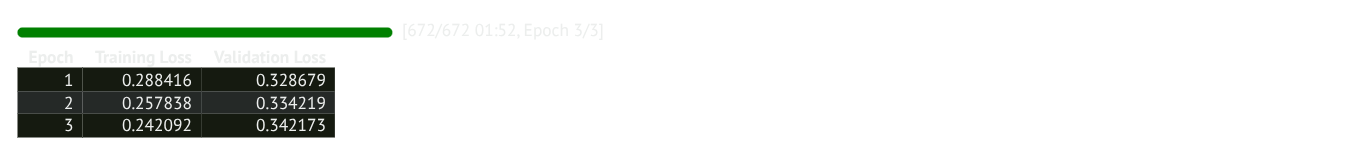

In [ ]:
# ───────────── stage: train (LoRA; every epoch's adapter + the resume checkpoint go to the model repo) ─────────────
from transformers import TrainerCallback as _TrainerCallback

def _encode(tok_, pairs_):
    rows_, too_long_ = [], 0
    for p_ in pairs_:
        ip_ = tok_(p_["prompt"], add_special_tokens=False)["input_ids"]
        ic_ = tok_(p_["completion"], add_special_tokens=False)["input_ids"]
        if len(ip_) + len(ic_) > MAX_LEN:
            too_long_ += 1
            continue
        rows_.append({"input_ids": ip_ + ic_, "attention_mask": [1] * (len(ip_) + len(ic_)), "labels": [-100] * len(ip_) + ic_})
    return rows_, too_long_

class _LossGuard(_TrainerCallback):
    """Abort on NaN or exploding loss (rule: never let a diverged run continue)."""
    def on_log(self, args, state, control, logs=None, **kw):
        loss_ = (logs or {}).get("loss")
        if loss_ is not None and state.global_step > 10 and (math.isnan(loss_) or loss_ > LOSS_ABORT):
            raise RuntimeError(f"loss guard: loss {loss_} at step {state.global_step}")

class _HubCheckpoints(_TrainerCallback):
    """After every save (one per epoch): the full checkpoint -> last-checkpoint/ (resume), the adapter -> epochs/epoch-N/."""
    def on_save(self, args, state, control, **kw):
        ck_ = WORK_DIR / "ckpt" / f"checkpoint-{state.global_step}"
        ep_ = int(round(state.epoch))
        wc.hf_model_upload_folder(ck_, MODEL_REPO, "last-checkpoint", f"{RUN_NAME}: checkpoint step {state.global_step}",
                                  HF_TOKEN, delete_patterns=["last-checkpoint/*"])
        ad_ = WORK_DIR / "epochs" / f"epoch-{ep_}"
        ad_.mkdir(parents=True, exist_ok=True)
        for f_ in ("adapter_model.safetensors", "adapter_config.json"):
            shutil.copy(ck_ / f_, ad_ / f_)
        (ad_ / "trainer_state.json").write_text((ck_ / "trainer_state.json").read_text())
        wc.hf_model_upload_folder(ad_, MODEL_REPO, f"epochs/epoch-{ep_}", f"{RUN_NAME}: adapter epoch {ep_}", HF_TOKEN)
        print(f"[train] epoch {ep_} saved (step {state.global_step}) -> {MODEL_REPO}/epochs/epoch-{ep_}", flush=True)

TRAIN_LOG = pd.DataFrame()
if stages.should_run("train"):
    from datasets import Dataset as _Dataset
    from peft import LoraConfig as _LoraConfig, get_peft_model as _get_peft_model
    from transformers import (AutoModelForCausalLM as _AMCL_t, AutoTokenizer as _AT_t, DataCollatorForSeq2Seq as _Collator,
                              Trainer as _Trainer, TrainingArguments as _TrainingArguments, set_seed as _set_seed)
    _set_seed(SEED)
    _tok = _AT_t.from_pretrained(BASE_MODEL, token=HF_TOKEN or None)
    if _tok.pad_token is None:
        _tok.pad_token = "<|finetune_right_pad_id|>" if "<|finetune_right_pad_id|>" in _tok.get_vocab() else _tok.eos_token
    _tok.padding_side = "right"
    _train, _tl = _encode(_tok, TRAIN_PAIRS)
    _val, _vl = _encode(_tok, VAL_PAIRS)
    # sanity: one begin-of-text at the start, the reply ends with <|eot_id|>, prompt tokens masked
    _bos, _eot = _tok.convert_tokens_to_ids("<|begin_of_text|>"), _tok.convert_tokens_to_ids("<|eot_id|>")
    _ex = _train[0]
    assert _ex["input_ids"][0] == _bos and _ex["input_ids"].count(_bos) == 1, "prompt must start with exactly one <|begin_of_text|>"
    assert _ex["input_ids"][-1] == _eot and _ex["labels"][-1] == _eot and _ex["labels"][0] == -100
    _n_lab = [sum(1 for l_ in r_["labels"] if l_ != -100) for r_ in _train]
    print(f"[train] {len(_train)} train / {len(_val)} validation examples ({_tl} + {_vl} longer than {MAX_LEN} dropped); "
          f"tokens per example mean {sum(len(r_['input_ids']) for r_ in _train) / len(_train):.0f}, reply tokens mean "
          f"{sum(_n_lab) / len(_n_lab):.0f}")
    assert _tl == 0, f"{_tl} training examples longer than MAX_LEN"
    _dt = torch.bfloat16 if BF16 else torch.float32
    try:
        _base = _AMCL_t.from_pretrained(BASE_MODEL, dtype=_dt, token=HF_TOKEN or None)
    except TypeError:
        _base = _AMCL_t.from_pretrained(BASE_MODEL, torch_dtype=_dt, token=HF_TOKEN or None)
    _model = _get_peft_model(_base, _LoraConfig(task_type="CAUSAL_LM", r=LORA["r"], lora_alpha=LORA["lora_alpha"],
                                              lora_dropout=LORA["lora_dropout"], target_modules=LORA["target_modules"]))
    for _n, _p in _model.named_parameters():  # adapters in fp32 (rule: trainable weights fp32, bf16 mixed precision)
        if _p.requires_grad:
            _p.data = _p.data.float()
    _model.print_trainable_parameters()
    # resume from the Hub (any machine)
    _resume = None
    _lc = wc.hf_model_download_folder(MODEL_REPO, "last-checkpoint", WORK_DIR / "hub", HF_TOKEN)
    if _lc is not None and (_lc / "trainer_state.json").exists():
        _resume = str(_lc)
        print(f"[train] resuming from {MODEL_REPO}/last-checkpoint")
    _args = _TrainingArguments(
        output_dir=str(WORK_DIR / "ckpt"), num_train_epochs=EPOCHS, per_device_train_batch_size=TRAIN_BATCH,
        per_device_eval_batch_size=TRAIN_BATCH, learning_rate=LEARNING_RATE, lr_scheduler_type=LR_SCHEDULER,
        # warm-up as steps (transformers 5.19 removed warmup_ratio): WARMUP_RATIO of all optimizer steps
        warmup_steps=int(math.ceil(WARMUP_RATIO * math.ceil(len(_train) / TRAIN_BATCH) * EPOCHS)), weight_decay=WEIGHT_DECAY, logging_steps=10, eval_strategy="epoch",
        save_strategy="epoch", save_total_limit=None, bf16=BF16, seed=SEED, data_seed=SEED, report_to="wandb" if wb else "none",
        run_name=RUN_NAME, remove_unused_columns=False, dataloader_num_workers=0,
        gradient_checkpointing=GRADIENT_CHECKPOINTING,
        gradient_checkpointing_kwargs={"use_reentrant": False} if GRADIENT_CHECKPOINTING else None)
    _trainer = _Trainer(model=_model, args=_args, train_dataset=_Dataset.from_list(_train), eval_dataset=_Dataset.from_list(_val),
                        data_collator=_Collator(_tok, padding=True, label_pad_token_id=-100),
                       callbacks=[_LossGuard(), _HubCheckpoints()])
    with wc.track_resources("train", log_fn=log_fn, csv_path=RESOURCES_CSV, n_examples=len(_train), epochs=EPOCHS) as _rec:
        _out = _trainer.train(resume_from_checkpoint=_resume)
        _rec["final_train_loss"] = round(float(_out.training_loss), 4)
        _rec["steps"] = int(_out.global_step)
    TRAIN_LOG = pd.DataFrame(_trainer.state.log_history)
    _lp = WORK_DIR / "train_log.csv"
    TRAIN_LOG.to_csv(_lp, index=False)
    wc.hf_upload(_lp, f"{wc.run_dir(RUN_NAME)}/train_log.csv", f"{RUN_NAME}: train log", HF_TOKEN)
    if RESOURCES_CSV.exists():
        wc.hf_upload(RESOURCES_CSV, f"{wc.run_dir(RUN_NAME)}/resources.csv", f"{RUN_NAME}: resources", HF_TOKEN)
    _ev = TRAIN_LOG.dropna(subset=["eval_loss"]) if "eval_loss" in TRAIN_LOG else pd.DataFrame()
    _epochs_done = sorted(int(p_.name.split("-")[1]) for p_ in (WORK_DIR / "epochs").glob("epoch-*"))
    assert _epochs_done, "no epoch adapter saved"
    assert not TRAIN_LOG.get("loss", pd.Series(dtype=float)).dropna().empty, "no training loss logged"
    print(f"[train] OK: final train loss {_out.training_loss:.4f}; validation loss by epoch "
          f"{[round(float(x_), 4) for x_ in _ev.get('eval_loss', [])]}; adapters {_epochs_done}")
    stages.mark_done("train", {"epochs": _epochs_done, "final_train_loss": float(_out.training_loss),
                               "eval_loss": [float(x_) for x_ in _ev.get("eval_loss", [])], "steps": int(_out.global_step)})
    del _trainer, _model, _base
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
else:
    _lp = wc.hf_download(f"{wc.run_dir(RUN_NAME)}/train_log.csv", WORK_DIR)
    TRAIN_LOG = wc.read_csv(_lp) if _lp else pd.DataFrame()
    print(f"[train] read back train log ({len(TRAIN_LOG)} rows)")

Loading weights: 100%|██████████| 146/146 [00:00<00:00, 2615.38it/s]
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[select] epoch 1: validation forced accepted 99.51% (loss 0.32867884635925293)


Loading weights: 100%|██████████| 146/146 [00:00<00:00, 2954.72it/s]


[select] epoch 2: validation forced accepted 100.0% (loss 0.3342193365097046)


Loading weights: 100%|██████████| 146/146 [00:00<00:00, 2557.37it/s]


[select] epoch 3: validation forced accepted 100.0% (loss 0.34217312932014465)
[select] best epoch: 2


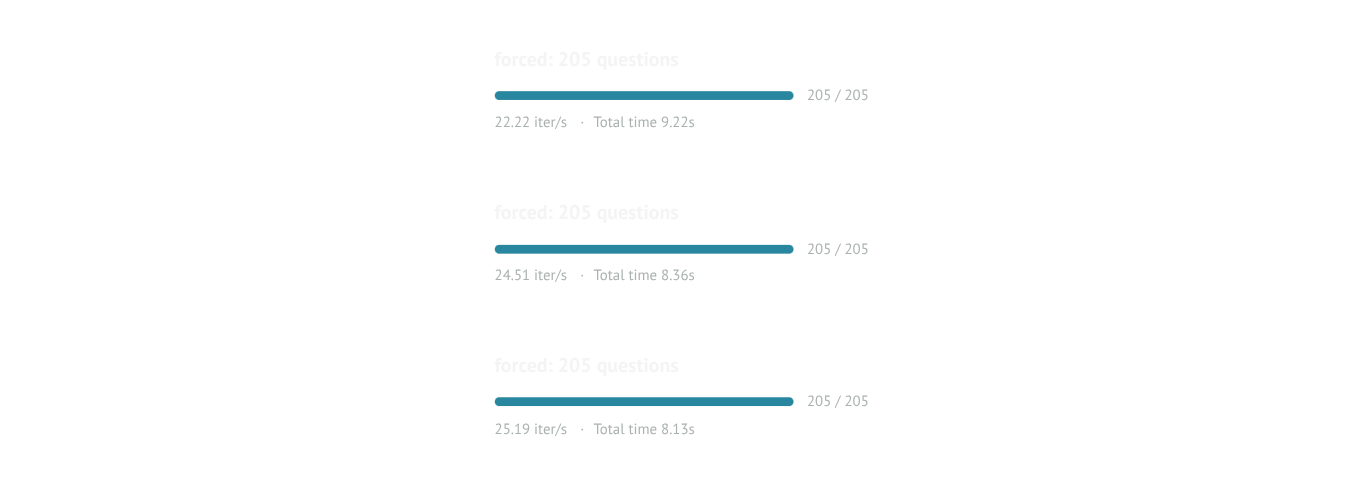

In [ ]:
# ───────────── stage: select (each epoch's adapter on VALIDATION, forced + JSON rule, strict scorer; never test) ─────────────
_marker = stages.marker("train") or {}
_epochs = _marker.get("epochs") or sorted(int(p_.name.split("-")[1]) for p_ in (WORK_DIR / "epochs").glob("epoch-*"))
SELECT = wc.hf_json(f"{wc.run_dir(RUN_NAME)}/select.json", WORK_DIR, HF_TOKEN) if not stages.should_run("select") else None
if SELECT is None and _epochs:
    _vloss = {}
    if not TRAIN_LOG.empty and "eval_loss" in TRAIN_LOG:
        for _r in TRAIN_LOG.dropna(subset=["eval_loss"]).to_dict("records"):
            _vloss[int(round(_r["epoch"]))] = float(_r["eval_loss"])
    _scores = []
    for _ep in _epochs:
        _ad = WORK_DIR / "epochs" / f"epoch-{_ep}"
        if not (_ad / "adapter_model.safetensors").exists():
            _ad = wc.hf_model_download_folder(MODEL_REPO, f"epochs/epoch-{_ep}", WORK_DIR / "hub", HF_TOKEN)
        _tok, _model, _stops = load_for_generation(BASE_MODEL, _ad)
        _cmp = compile_grammar(_tok, _model) if xgr is not None else None
        _df = run_forced(_tok, _model, _stops, _cmp, ITEMS_FORCED["validation"])
        _sc = pd.DataFrame([wc.score_part(str(r_["output"]), r_["part"], r_["verb"], REFS[r_["verb"]], str(r_["ref_answer"]))
                            for r_ in _df.to_dict("records")])
        _acc = round(100 * float(_sc["accepted"].mean()), 2)
        _scores.append({"epoch": _ep, "val_forced_schema_accepted_pct": _acc, "val_loss": _vloss.get(_ep),
                        "val_answer_matches_ref_pct": round(100 * float(_sc["answer_matches_ref"].mean()), 2)})
        print(f"[select] epoch {_ep}: validation forced accepted {_acc}% (loss {_vloss.get(_ep)})")
        del _model
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    _best = sorted(_scores, key=lambda s_: (-s_["val_forced_schema_accepted_pct"], s_["val_loss"] if s_["val_loss"] is not None else 9e9))[0]
    SELECT = {"best_epoch": _best["epoch"], "scores": _scores, "rule": "max validation forced-schema accepted %, ties -> lower validation loss"}
    wc.put_json(SELECT, f"{wc.run_dir(RUN_NAME)}/select.json", WORK_DIR, f"{RUN_NAME}: checkpoint selection", HF_TOKEN)
    stages.mark_done("select", SELECT)
    if log_fn:
        log_fn({"select/best_epoch": _best["epoch"], "select/val_forced_schema_accepted_pct": _best["val_forced_schema_accepted_pct"]})
print(f"[select] best epoch: {SELECT['best_epoch'] if SELECT else None}")

In [ ]:
# ───────────── stage: merge (best adapter into the base model, bf16 safetensors at the model repo root) ─────────────
MERGED_DIR = WORK_DIR / "merged"
if SELECT and stages.should_run("merge"):
    from peft import PeftModel as _PeftModel
    from transformers import AutoModelForCausalLM as _AMCL_m, AutoTokenizer as _AT_m
    _ep = SELECT["best_epoch"]
    _ad = WORK_DIR / "epochs" / f"epoch-{_ep}"
    if not (_ad / "adapter_model.safetensors").exists():
        _ad = wc.hf_model_download_folder(MODEL_REPO, f"epochs/epoch-{_ep}", WORK_DIR / "hub", HF_TOKEN)
    with mo.status.spinner(title=f"Merging epoch {_ep} into {BASE_MODEL}"):
        try:  # merge in fp32, save in bf16
            _base = _AMCL_m.from_pretrained(BASE_MODEL, dtype=torch.float32, token=HF_TOKEN or None)
        except TypeError:
            _base = _AMCL_m.from_pretrained(BASE_MODEL, torch_dtype=torch.float32, token=HF_TOKEN or None)
        _merged = _PeftModel.from_pretrained(_base, str(_ad)).merge_and_unload().to(torch.bfloat16)
        MERGED_DIR.mkdir(parents=True, exist_ok=True)
        _merged.save_pretrained(str(MERGED_DIR), safe_serialization=True)
        _AT_m.from_pretrained(BASE_MODEL, token=HF_TOKEN or None).save_pretrained(str(MERGED_DIR))
        (MERGED_DIR / "README.md").write_text(
            f"# {RUN_NAME}\n\nLlama-3.2-1B-Instruct fine-tuned with LoRA (merged; epoch {_ep}) to write VNeST aphasia exercises one "
            f"question per request (VNeST Practice app). Training data: dataset v2 (private). Built with Llama; use is subject to the "
            f"Llama 3.2 Community License. Research model: not reviewed by a therapist.\n")
        del _base, _merged
        gc.collect()
    wc.hf_model_upload_folder(MERGED_DIR, MODEL_REPO, "", f"{RUN_NAME}: merged model (epoch {_ep})", HF_TOKEN)
    stages.mark_done("merge", {"best_epoch": _ep, "repo": MODEL_REPO})
    print(f"[merge] epoch {_ep} merged -> {MODEL_REPO} (root)")
elif SELECT and not (MERGED_DIR / "config.json").exists():
    _got = wc.hf_model_download_folder(MODEL_REPO, "", WORK_DIR / "hub_merged", HF_TOKEN)
    MERGED_DIR = _got if _got is not None else MERGED_DIR
    print(f"[merge] read back merged model from {MODEL_REPO}")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.04it/s]
/usr/local/lib/python3.13/site-packages/huggingface_hub/hf_api.py:11391: UserWarning: Warnings while validating metadata in README.md:
- empty or missing yaml metadata in repo card
  warnings.warn(f"Warnings while validating metadata in README.md:\n{message}")


[merge] epoch 2 merged -> emmilly/vnest-exercise-llm-f1-llama32-1b-instruct-lora-r16 (root)


[hf] download runs/f1-llama32-1b-instruct-lora-r16/raw/finetuned__validation__forced-schema.csv: 404 Client Error. (Request ID: Root=1-6af42b49-228210cf4a8a42902bfb8e18;fae60c5e-808e-4971-be60-eafbbf2f6f72)

Entry Not -> retry in 5s


Loading weights: 100%|██████████| 146/146 [00:00<00:00, 2706.53it/s]


[eval] loaded finetuned from /home/marimo/vnest/runs/f1-llama32-1b-instruct-lora-r16/merged | stop tokens [128001, 128008, 128009]
[resources] eval-finetuned-validation-forced-schema: ok | 0.0013 h | peak GPU 2.92 GB | 1592.5 tok/s
[eval] finetuned/validation/forced-schema: 205 outputs, 0 empty, 94 distinct, mean 36 tokens, 0 cut off at 48
[resources] eval-finetuned-validation-forced-free: ok | 0.0011 h | peak GPU 2.92 GB | 1854.6 tok/s
[eval] finetuned/validation/forced-free: 205 outputs, 0 empty, 94 distinct, mean 36 tokens, 0 cut off at 48
[resources] eval-finetuned-validation-chain-schema: ok | 0.0015 h | peak GPU 2.92 GB | 1302.2 tok/s
[eval] finetuned/validation/chain-schema: 205 outputs, 0 empty, 173 distinct, mean 35 tokens, 0 cut off at 48, passed 100% of tries
[resources] eval-finetuned-validation-chain-free: ok | 0.0014 h | peak GPU 2.92 GB | 1445.7 tok/s
[eval] finetuned/validation/chain-free: 205 outputs, 0 empty, 173 distinct, mean 35 tokens, 0 cut off at 48, passed 100% 

Loading weights: 100%|██████████| 146/146 [00:00<00:00, 4492.50it/s]


[eval] loaded base from meta-llama/Llama-3.2-1B-Instruct | stop tokens [128001, 128008, 128009]
[resources] eval-base-validation-forced-schema: ok | 0.0013 h | peak GPU 2.92 GB | 1655.6 tok/s
[eval] base/validation/forced-schema: 205 outputs, 0 empty, 127 distinct, mean 37 tokens, 34 cut off at 48
[resources] eval-base-validation-forced-free: ok | 0.0012 h | peak GPU 2.92 GB | 1805.1 tok/s
[eval] base/validation/forced-free: 205 outputs, 0 empty, 128 distinct, mean 37 tokens, 34 cut off at 48
[resources] eval-base-validation-chain-schema: ok | 0.0014 h | peak GPU 2.92 GB | 1145.7 tok/s
[eval] base/validation/chain-schema: 167 outputs, 0 empty, 128 distinct, mean 35 tokens, 9 cut off at 48, passed 20% of tries
[resources] eval-base-validation-chain-free: ok | 0.0013 h | peak GPU 2.92 GB | 1358.6 tok/s
[eval] base/validation/chain-free: 175 outputs, 0 empty, 132 distinct, mean 35 tokens, 7 cut off at 48, passed 19% of tries
[resources] eval-base-test-forced-schema: ok | 0.0022 h | peak G

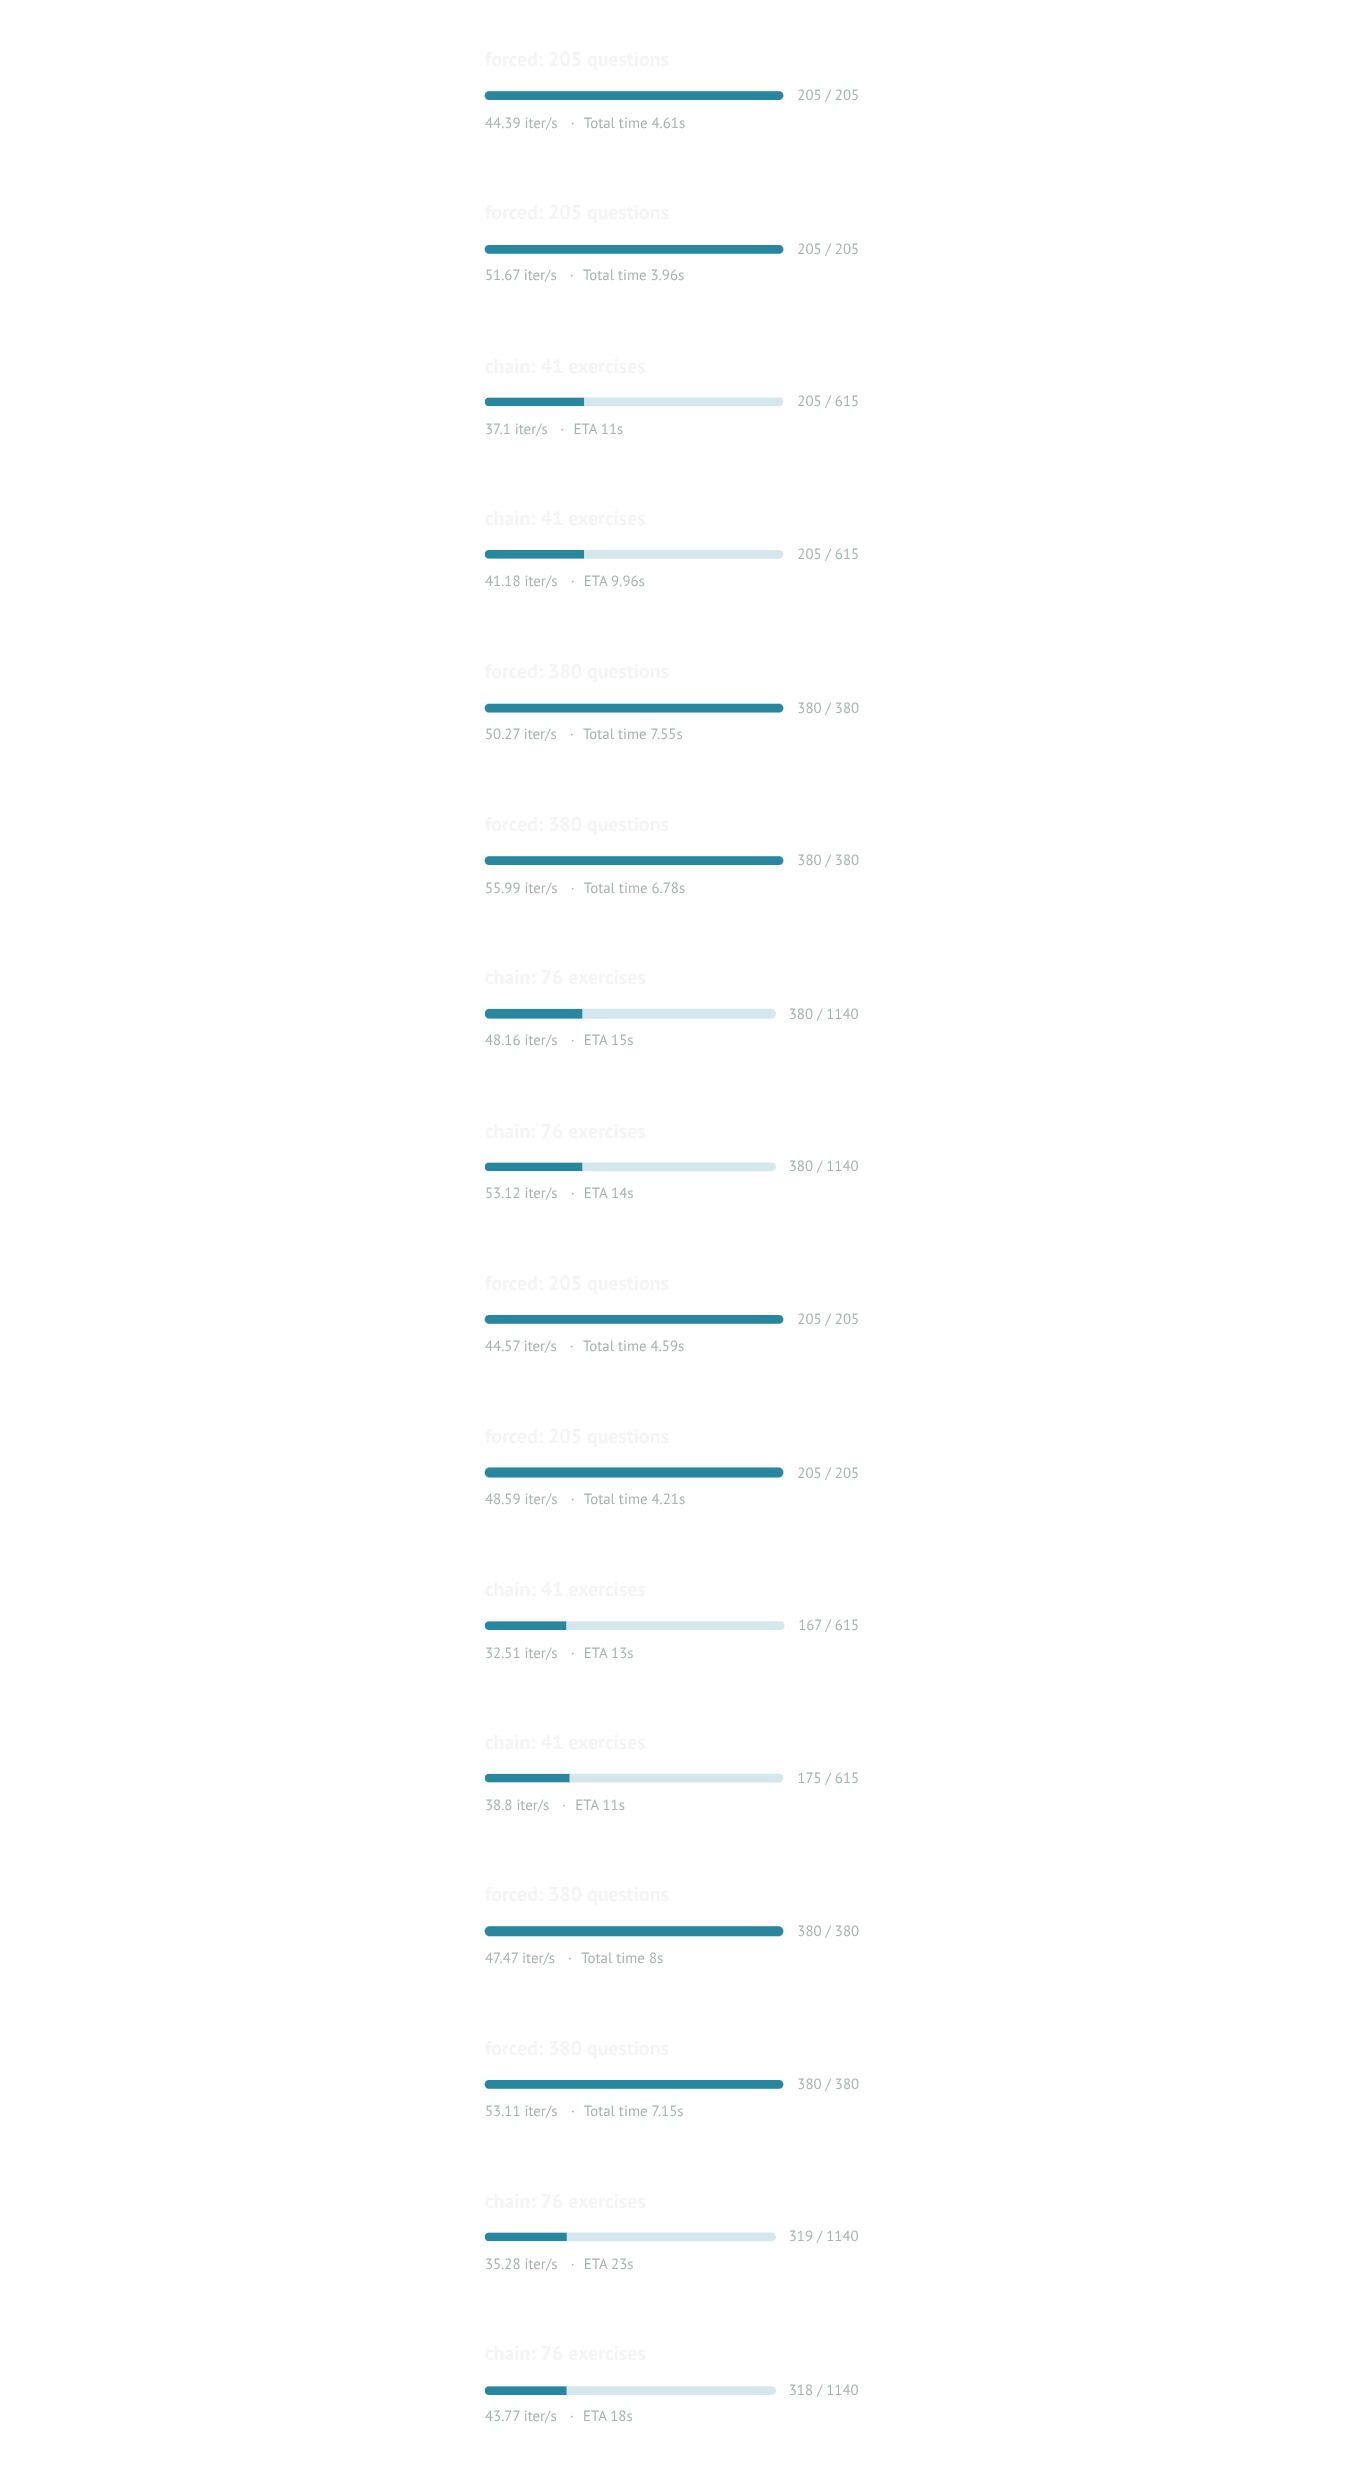

In [ ]:
# ───────────── stage: eval (fine-tuned + untuned base control; each part saved to HF as soon as it finishes) ─────────────
PARTS = [(m, s, p, d) for m in EVAL_MODELS for s in SPLITS for p in PROTOCOLS for d in DECODINGS]

def _raw_path(m_, s_, p_, d_):
    return f"{wc.run_dir(RUN_NAME)}/raw/{m_}__{s_}__{p_}-{d_}.csv"

RAW = {}
_run_eval = stages.should_run("eval")
_loaded, _tok, _model, _stops, _cmp = None, None, None, None, None
for _m, _split, _proto, _dec in PARTS:
    _path = _raw_path(_m, _split, _proto, _dec)
    _local = wc.hf_download(_path, WORK_DIR) if "eval" not in stages.force else None
    if _local is not None:
        RAW[(_m, _split, _proto, _dec)] = wc.read_csv(_local)
        continue
    if not _run_eval:
        continue
    if _dec == "schema" and xgr is None:
        print(f"[eval] {_m}/{_split}/{_proto}-{_dec}: SKIPPED, xgrammar unavailable ({XGR_ERROR})")
        continue
    if _loaded != _m:
        if _model is not None:
            del _model
            gc.collect()
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
        _src = str(MERGED_DIR) if _m == "finetuned" else BASE_MODEL
        with mo.status.spinner(title=f"Loading {_m} ({_src})"):
            _tok, _model, _stops = load_for_generation(_src)
        _cmp = compile_grammar(_tok, _model) if xgr is not None else None
        _loaded = _m
        print(f"[eval] loaded {_m} from {_src} | stop tokens {_stops}")
    _items = ITEMS_FORCED[_split] if _proto == "forced" else ITEMS_CHAIN[_split]
    with wc.track_resources(f"eval-{_m}-{_split}-{_proto}-{_dec}", log_fn=log_fn, csv_path=RESOURCES_CSV, n_items=len(_items)) as _rec:
        _df = (run_forced if _proto == "forced" else run_chain)(_tok, _model, _stops, _cmp if _dec == "schema" else None, _items)
        _df["model"], _df["protocol"], _df["decoding"] = _m, _proto, _dec
        _rec["gen_tokens"] = int(_df["gen_tokens"].sum())
    _n_empty = int((_df["output"].astype(str).str.strip() == "").sum())
    _extra = f", passed {_df['passed'].mean():.0%} of tries" if _proto == "chain" else ""
    print(f"[eval] {_m}/{_split}/{_proto}-{_dec}: {len(_df)} outputs, {_n_empty} empty, {_df['output'].nunique()} distinct, "
          f"mean {_df['gen_tokens'].mean():.0f} tokens, {int(_df['hit_token_limit'].sum())} cut off at {MAX_NEW_TOKENS}{_extra}")
    assert _n_empty < len(_df), "every output empty: something is wrong"
    _lp = WORK_DIR / _path
    _lp.parent.mkdir(parents=True, exist_ok=True)
    _df.to_csv(_lp, index=False)
    wc.hf_upload(_lp, _path, f"{RUN_NAME}: raw {_m}/{_split}/{_proto}-{_dec}", HF_TOKEN)
    RAW[(_m, _split, _proto, _dec)] = _df
if _model is not None:
    del _model
    gc.collect()
if _run_eval:
    if RESOURCES_CSV.exists():
        wc.hf_upload(RESOURCES_CSV, f"{wc.run_dir(RUN_NAME)}/resources.csv", f"{RUN_NAME}: resources", HF_TOKEN)
    _missing = [k_ for k_ in PARTS if k_ not in RAW]
    if not _missing:
        stages.mark_done("eval", {"parts": ["/".join(k_) for k_ in PARTS]})
    else:
        print(f"[eval] NOT marked done; missing parts: {_missing}")
print(f"[eval] {len(RAW)}/{len(PARTS)} parts available")

In [ ]:
# ───────────── stage: score (re-runs automatically if the raw outputs changed) ─────────────
def _fingerprint(raw_):
    h_ = hashlib.md5()
    for k_ in sorted(raw_):
        h_.update(str(k_).encode())
        h_.update(raw_[k_][["output"]].to_csv(index=False).encode())
    return h_.hexdigest()

def _save(df_, split_, variant_):
    path_ = wc.preds_path(EXP_ID, NOTEBOOK, RUN_NAME, split_, variant_)
    lp_ = WORK_DIR / path_
    lp_.parent.mkdir(parents=True, exist_ok=True)
    df_.to_csv(lp_, index=False)
    wc.hf_upload(lp_, path_, f"{RUN_NAME}: scored {split_}/{variant_}", HF_TOKEN)
    return path_

_tag = {"exp_id": EXP_ID, "notebook": NOTEBOOK, "run_name": RUN_NAME}
FP = _fingerprint(RAW)
_marker = stages.marker("score")
_stale = bool(_marker) and _marker.get("raw_fingerprint") != FP
if _stale:
    print(f"[score] raw outputs changed since last scoring: re-scoring")
SCORED, ATTEMPTS = {}, {}
if RAW and (_stale or stages.should_run("score")):
    for (_m, _split, _proto, _dec), _raw in RAW.items():
        _recs = _raw.to_dict("records")
        _v = f"{_m}-{_proto}-{_dec}"
        if _proto == "forced":
            _df = pd.DataFrame([{**_tag, **_r, **wc.score_part(str(_r["output"]), _r["part"], _r["verb"], REFS[_r["verb"]],
                                                               str(_r["ref_answer"]))} for _r in _recs])
            _path = _save(_df, _split, _v)
            print(f"[score] {_m}/{_split}/forced-{_dec}: accepted {_df['accepted'].mean():.0%} of questions, "
                  f"matches reference {_df['answer_matches_ref'].mean():.0%}, echoes {_df['echoes_instructions'].mean():.0%} -> {_path}")
        else:
            _att = pd.DataFrame([{**_tag, **_r, **{f"q_{k}": v for k, v in wc.score_part(
                str(_r["output"]), _r["part"], _r["verb"], REFS[_r["verb"]]).items()}} for _r in _recs])
            ATTEMPTS[(_m, _split, _proto, _dec)] = _att
            _save(_att, _split, f"{_v}-attempts")
            _ex_rows = []
            for _it in ITEMS_CHAIN[_split]:
                _mine = [_r for _r in _recs if _r["exercise_id"] == _it["exercise_id"]]
                _byp = {}
                for _r in sorted(_mine, key=lambda r: (wc.QUESTIONS.index(r["part"]), int(r["try"]))):
                    _byp.setdefault(_r["part"], []).append(str(_r["output"]))
                _ch = wc.score_chain(_byp, _it["verb"], REFS[_it["verb"]])
                _loop_ok = all(any(_r["passed"] in (True, "True", "true") for _r in _mine if _r["part"] == _p) for _p in wc.QUESTIONS)
                assert _ch["exercise_accepted"] == _loop_ok, (_it["exercise_id"], _ch)  # same module for generation and scoring
                _final = {f"{_p}_answer": next(((wc.extract_json(str(_r["output"]))[0] or {}).get("answer", "") for _r in _mine
                                               if _r["part"] == _p and _r["passed"] in (True, "True", "true")), "") for _p in wc.QUESTIONS}
                _ex_rows.append({**_tag, "model": _m, "split": _split, "exercise_id": _it["exercise_id"], "verb": _it["verb"],
                                 "protocol": "chain", "decoding": _dec, **_ch, **_final,
                                 "gen_tokens": int(sum(int(_r["gen_tokens"]) for _r in _mine))})
            _df = pd.DataFrame(_ex_rows)
            _path = _save(_df, _split, _v)
            print(f"[score] {_m}/{_split}/chain-{_dec}: {_df['exercise_accepted'].mean():.0%} of exercises completed, "
                  f"mean {_df['total_tries'].mean():.1f} tries; failed at {_df['failed_part'].replace('', 'none').value_counts().to_dict()} -> {_path}")
        SCORED[(_m, _split, _proto, _dec)] = _df
    stages.mark_done("score", {"raw_fingerprint": FP, "parts": len(SCORED)})
else:
    for (_m, _split, _proto, _dec) in RAW:
        _v = f"{_m}-{_proto}-{_dec}"
        _local = wc.hf_download(wc.preds_path(EXP_ID, NOTEBOOK, RUN_NAME, _split, _v), WORK_DIR)
        if _local is not None:
            SCORED[(_m, _split, _proto, _dec)] = wc.read_csv(_local)
        if _proto == "chain":
            _la = wc.hf_download(wc.preds_path(EXP_ID, NOTEBOOK, RUN_NAME, _split, f"{_v}-attempts"), WORK_DIR)
            if _la is not None:
                ATTEMPTS[(_m, _split, _proto, _dec)] = wc.read_csv(_la)
    print(f"[score] read back {len(SCORED)} scored parts")

[score] finetuned/validation/forced-schema: accepted 100% of questions, matches reference 35%, echoes 0% -> preds/f1__1.01__f1-llama32-1b-instruct-lora-r16__validation__finetuned-forced-schema.csv
[score] finetuned/validation/forced-free: accepted 100% of questions, matches reference 35%, echoes 0% -> preds/f1__1.01__f1-llama32-1b-instruct-lora-r16__validation__finetuned-forced-free.csv
[score] finetuned/validation/chain-schema: 100% of exercises completed, mean 5.0 tries; failed at {'none': 41} -> preds/f1__1.01__f1-llama32-1b-instruct-lora-r16__validation__finetuned-chain-schema.csv
[score] finetuned/validation/chain-free: 100% of exercises completed, mean 5.0 tries; failed at {'none': 41} -> preds/f1__1.01__f1-llama32-1b-instruct-lora-r16__validation__finetuned-chain-free.csv
[score] finetuned/test/forced-schema: accepted 100% of questions, matches reference 36%, echoes 0% -> preds/f1__1.01__f1-llama32-1b-instruct-lora-r16__test__finetuned-forced-schema.csv
[score] finetuned/test/fo

[summary] forced-summary -> tables/f1__1.01__forced-summary.csv
[summary] forced-by-part -> tables/f1__1.01__forced-by-part.csv
[summary] chain-summary -> tables/f1__1.01__chain-summary.csv
[summary] per-verb -> tables/f1__1.01__per-verb.csv


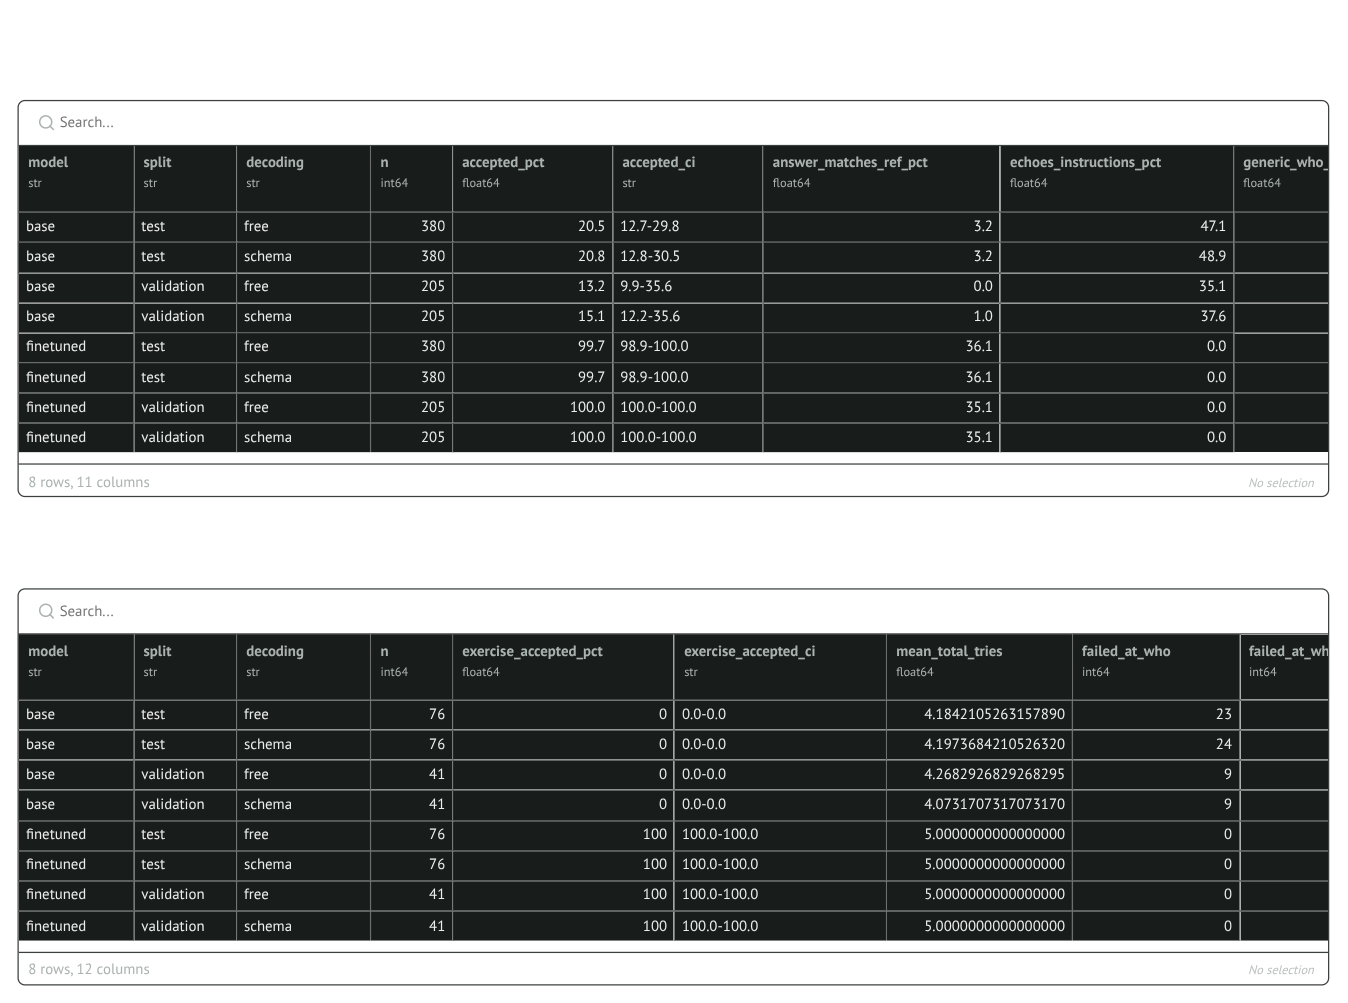

In [ ]:
# ───────────── stage: summary tables (always recomputed from the scored outputs) ─────────────
def _bools(df_, cols_):
    for c_ in cols_:
        if c_ in df_:
            df_[c_] = df_[c_].astype(str).str.lower().isin(["true", "1"]) if df_[c_].dtype == object else df_[c_].astype(bool)
    return df_

def _put(df_, what_):
    path_ = wc.table_path(EXP_ID, NOTEBOOK, what_)
    lp_ = WORK_DIR / path_
    lp_.parent.mkdir(parents=True, exist_ok=True)
    df_.to_csv(lp_, index=False)
    wc.hf_upload(lp_, path_, f"{RUN_NAME}: {path_}", HF_TOKEN)
    return path_

_ep = SELECT["best_epoch"] if SELECT else None
_names = {"finetuned": f"Llama-3.2-1B-Instruct + LoRA r16 (epoch {_ep}, merged, bf16)", "base": "Llama-3.2-1B-Instruct (untuned, bf16)"}
_f = [v for (m_, s_, p_, d_), v in SCORED.items() if p_ == "forced"]
_c = [v for (m_, s_, p_, d_), v in SCORED.items() if p_ == "chain"]
FORCED = _bools(pd.concat(_f, ignore_index=True), wc.PART_METRICS) if _f else pd.DataFrame()
CHAIN = _bools(pd.concat(_c, ignore_index=True), wc.CHAIN_METRICS) if _c else pd.DataFrame()
TABLES = {}
if not FORCED.empty:
    TABLES["forced-summary"] = wc.summarise(FORCED, ["model", "split", "decoding"], metrics=wc.PART_METRICS)
    TABLES["forced-by-part"] = wc.summarise(FORCED, ["model", "split", "decoding", "part"], metrics=wc.PART_METRICS)
if not CHAIN.empty:
    _cs = wc.summarise(CHAIN, ["model", "split", "decoding"], metrics=wc.CHAIN_METRICS)
    _extra = CHAIN.groupby(["model", "split", "decoding"]).agg(
        mean_total_tries=("total_tries", "mean"),
        **{f"failed_at_{p}": ("failed_part", lambda s, p=p: int((s == p).sum())) for p in wc.QUESTIONS}).reset_index()
    TABLES["chain-summary"] = _cs.merge(_extra, on=["model", "split", "decoding"])
_pv = []
if not FORCED.empty:
    _pv.append(wc.summarise(FORCED[FORCED["split"] == "test"], ["model", "decoding", "verb"], metrics=["accepted"]).assign(protocol="forced"))
if not CHAIN.empty:
    _pv.append(wc.summarise(CHAIN[CHAIN["split"] == "test"], ["model", "decoding", "verb"], metrics=wc.CHAIN_METRICS).assign(protocol="chain"))
if _pv:
    TABLES["per-verb"] = pd.concat(_pv, ignore_index=True)
for _what, _df in TABLES.items():
    _df.insert(1, "model_name", _df["model"].map(_names))
    print(f"[summary] {_what} -> {_put(_df, _what)}")
if TABLES:
    if log_fn:
        for _r in TABLES.get("forced-summary", pd.DataFrame()).to_dict("records"):
            log_fn({f"forced/{_r['model']}/{_r['split']}/{_r['decoding']}/{m}_pct": _r[f"{m}_pct"] for m in wc.PART_METRICS})
        for _r in TABLES.get("chain-summary", pd.DataFrame()).to_dict("records"):
            log_fn({f"chain/{_r['model']}/{_r['split']}/{_r['decoding']}/exercise_accepted_pct": _r["exercise_accepted_pct"]})
    stages.mark_done("summary", {"tables": [wc.table_path(EXP_ID, NOTEBOOK, w) for w in TABLES]})
else:
    print("[summary] nothing scored yet: no tables written")
_show_f = ["model", "split", "decoding", "n", "accepted_pct", "accepted_ci", "answer_matches_ref_pct", "echoes_instructions_pct",
           "generic_who_pct", "any_bad_distractor_pct", "mean_gen_tokens"]
_show_c = ["model", "split", "decoding", "n", "exercise_accepted_pct", "exercise_accepted_ci", "mean_total_tries"] + \
          [f"failed_at_{p}" for p in wc.QUESTIONS]
_tf, _tc = TABLES.get("forced-summary", pd.DataFrame()), TABLES.get("chain-summary", pd.DataFrame())
mo.vstack([mo.md(f"### Forced: each question on its own (best epoch {_ep}; automatic scores; test = 5 verbs)"),
           mo.ui.table(_tf[[c for c in _show_f if c in _tf]] if not _tf.empty else _tf, selection=None),
           mo.md("### Chain: whole exercises written the app's way (≤ 3 tries per question)"),
           mo.ui.table(_tc[[c for c in _show_c if c in _tc]] if not _tc.empty else _tc, selection=None)])

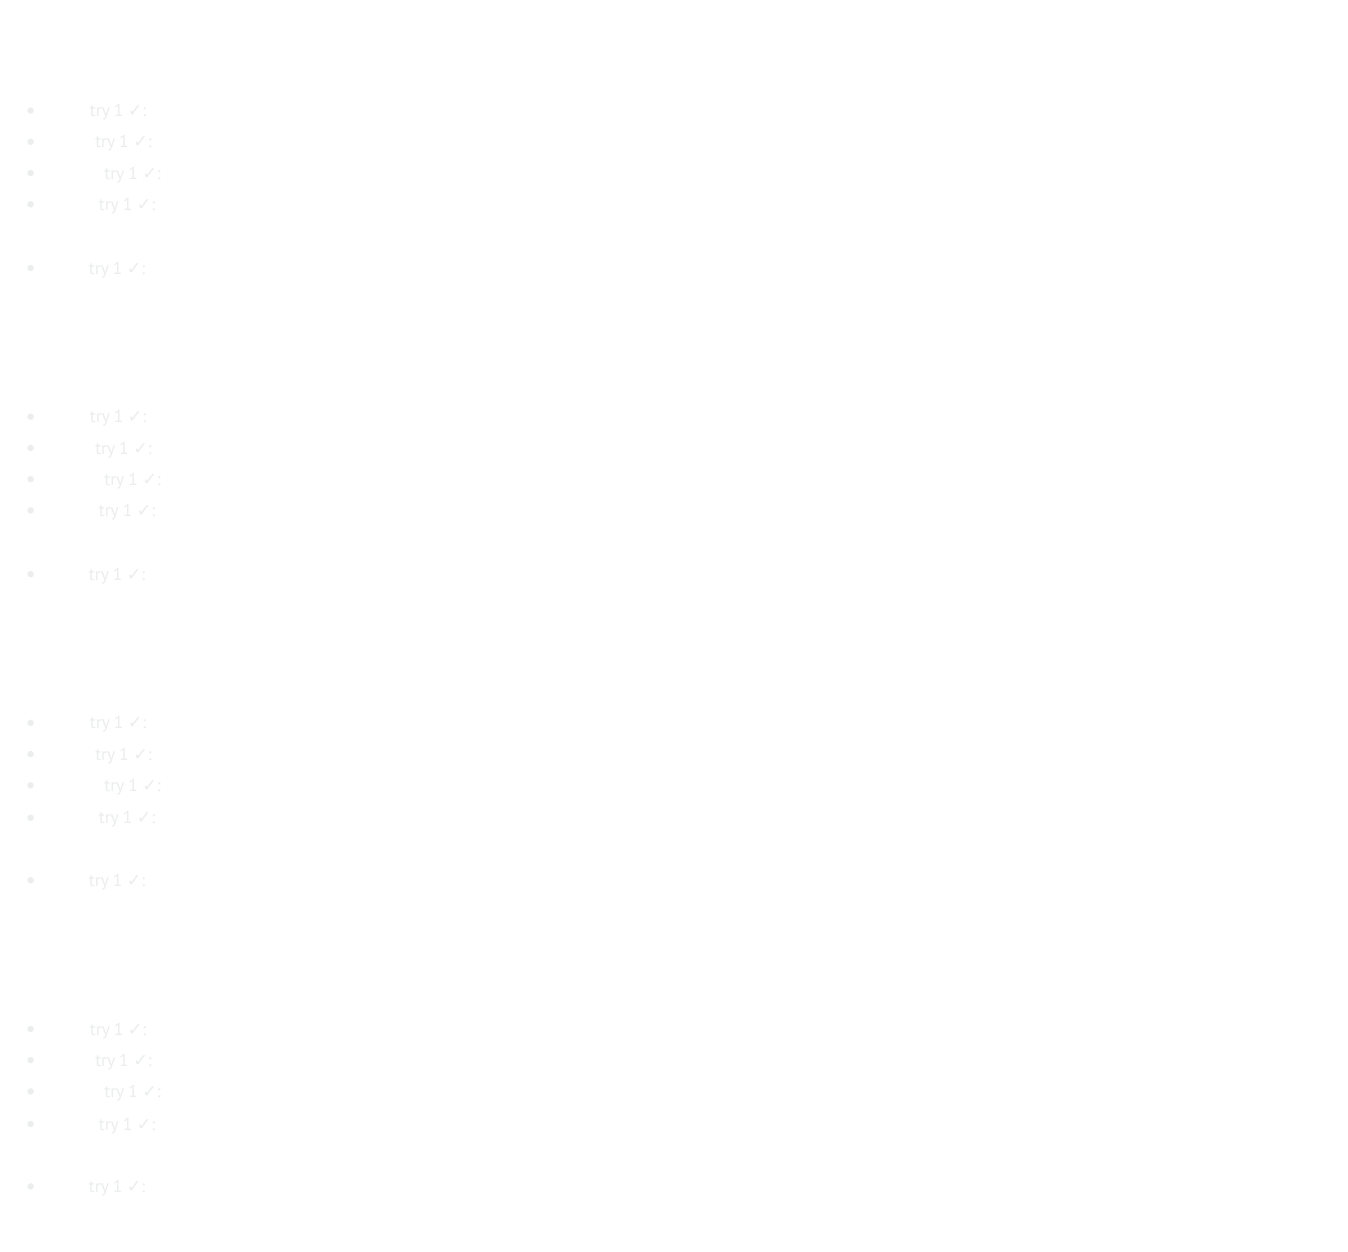

In [ ]:
# Two chained test exercises of the fine-tuned model per decoding, with every try, to read
_blocks = []
for (_m, _s, _p, _d), _att in sorted(ATTEMPTS.items()):
    if _s != "test" or _m != "finetuned":
        continue
    for _ex in list(dict.fromkeys(_att["exercise_id"]))[:2]:
        _rows = _att[_att["exercise_id"] == _ex]
        _txt = "\n".join(f"- **{r.part}** try {r.try_} {'✓' if str(r.passed).lower() == 'true' else '✗ ' + str(r.reason)}: `{str(r.output)[:200]}`"
                         for r in _rows.rename(columns={"try": "try_"}).itertuples())
        _blocks.append(mo.md(f"#### fine-tuned · {_d} decoding · {_ex}\n\n{_txt}"))
mo.vstack(_blocks) if _blocks else mo.md("_no chained outputs yet_")

In [ ]:
# ───────────── finish: outcome tag, close W&B ─────────────
if wb is not None:
    try:
        import wandb as _wandb
        for _what, _df in TABLES.items():
            wb.log({f"{_what}_table": _wandb.Table(dataframe=_df)})
    except Exception as _e:
        print(f"[wandb] final logging skipped: {str(_e)[:80]}")
    wb.finish()
print("done. Next: compare f1 with the base control and b2 (tables/f1__1.01__*.csv), log Entry 11, then convert the merged model "
      "for the phone (tools/build_phone_models.sh: q4f16_0, library llama1b_q4f16_0).")

wandb: uploading artifact run-f1-llama32-1b-instruct-lora-r16-forced-summary_table; uploading artifact run-f1-llama32-1b-instruct-lora-r16-forced-by-part_table; uploading artifact run-f1-llama32-1b-instruct-lora-r16-chain-summary_table; uploading artifact run-f1-llama32-1b-instruct-lora-r16-per-verb_table; updating run metadata
wandb: uploading artifact run-f1-llama32-1b-instruct-lora-r16-forced-summary_table; uploading artifact run-f1-llama32-1b-instruct-lora-r16-forced-by-part_table; uploading artifact run-f1-llama32-1b-instruct-lora-r16-chain-summary_table; uploading artifact run-f1-llama32-1b-instruct-lora-r16-per-verb_table
wandb: uploading artifact run-f1-llama32-1b-instruct-lora-r16-forced-by-part_table; uploading artifact run-f1-llama32-1b-instruct-lora-r16-chain-summary_table; uploading artifact run-f1-llama32-1b-instruct-lora-r16-per-verb_table
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml; uploading media/table/forced-summary_table_71_771d2

done. Next: compare f1 with the base control and b2 (tables/f1__1.01__*.csv), log Entry 11, then convert the merged model for the phone (tools/build_phone_models.sh: q4f16_0, library llama1b_q4f16_0).
